# Linesearch Implicit NN From Spring Data

This notebook generates target geometries with `SpringFF`, then trains `NNPotentialFF` with `LinesearchImplicitMultipleSystemOptimizer`. This optimizer avoids exact line minimization, which can be awkward for neural-network potentials.


In [ ]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..')))

import copy
import torch
import numpy as np
import matplotlib.pyplot as plt

from geomatry.opt_Energy_approximated.optimizer import ExactLineSearchLinesearchImplicitMultipleSystemOptimizer as LinesearchImplicitMultipleSystemOptimizer
from geomatry.opt.loss import rmsd_loss
from geomatry.ff.graph import get_given_graph_builder
from geomatry.ff.springs import SpringFF, _random_spring_systems, _random_spring_ff_param
from geomatry.ff.NN import NNPotentialFF


In [2]:
def min_pair_distance(Ra: torch.Tensor) -> float:
    Ra = Ra.detach()
    dmat = torch.cdist(Ra, Ra)
    return float(torch.min(dmat + torch.eye(Ra.shape[0], device=Ra.device) * 1e6))


In [3]:
systemN = 40
N = 8
N_pairs = 12
max_Za = 1
fixed_atom_indices = [0,1,2]

Ras, Zas, idx_is, idx_js = _random_spring_systems(systemN, N, N_pairs, max_Za, start_Za=1)
k, r0 = _random_spring_ff_param(max_Za, k_max=2.0, r0_max=1.5)

target_ff = SpringFF(max_Za)
target_ff.reset_parameters(k, r0)
params_star = copy.deepcopy(target_ff.state_dict())

graph_builders = [get_given_graph_builder(idx_i, idx_j) for idx_i, idx_j in zip(idx_is, idx_js)]

print('sample target k', k[1:, 1:].mean().item())
print('sample target r0', r0[1:, 1:].mean().item())
print('sample min distances', [min_pair_distance(Ra) for Ra in Ras[:3]])


sample target k 1.2711559012261309
sample target r0 0.4294218674234277
sample min distances [0.9975434454406926, 0.5374909546891196, 0.39443274475636925]


In [ ]:
# Use SpringFF only to generate target optimized geometries.
target_optimizer = LinesearchImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, target_ff, rmsd_loss,
    params_star=params_star,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)
Ra_star_list = target_optimizer.Ra_stars

from geomatry.opt_Energy_approximated.calculator import get_ase_atoms

with torch.no_grad():
    target_energies = torch.stack([
        target_ff.get_E(Ra_star, Za, *graph_builder(get_ase_atoms(Ra_star, Za))).detach()
        for Ra_star, Za, graph_builder in zip(Ra_star_list, Zas, graph_builders)
    ]).float()

# Train the NN force field with Linesearch implicit gradients.
ff = NNPotentialFF(max_Za, hidden_dim=24)
optimizer = LinesearchImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, ff, rmsd_loss,
    Ra_stars=Ra_star_list,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)
params_0 = copy.deepcopy(ff.state_dict())

print('target geometries', len(Ra_star_list))
print('NN parameter tensors', len(params_0))


target geometries 40
NN parameter tensors 18


In [5]:
def predict_system_energy(nn_ff, Ra, Za, graph_builder):
    return nn_ff.get_E(Ra.float(), Za.long(), *graph_builder(get_ase_atoms(Ra, Za)))

def batch_predict(nn_ff):
    return torch.stack([
        predict_system_energy(nn_ff, Ra_star, Za, graph_builder)
        for Ra_star, Za, graph_builder in zip(Ra_star_list, Zas, graph_builders)
    ])
device = torch.device("cpu")
nn_ff = NNPotentialFF(max_Za, hidden_dim=32).to(device)
optimizer = torch.optim.Adam(nn_ff.parameters(), lr=3e-3, weight_decay=1e-6)
loss_history = []

from tqdm import tqdm

epochs = 11
print_period = 10
pbar = tqdm(range(epochs), desc="NN spring training")
for epoch in pbar:
    optimizer.zero_grad()
    y_pred = batch_predict(nn_ff)
    loss = torch.mean((y_pred - target_energies) ** 2)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

    if epoch % print_period == 0 or epoch == epochs - 1:
        with torch.no_grad():
            errors = batch_predict(nn_ff) - target_energies
            rmse = torch.sqrt(torch.mean(errors ** 2)).item()
            mae = torch.mean(torch.abs(errors)).item()
        pbar.set_postfix(loss=f"{loss.item():.6e}", rmse=f"{rmse:.6f}", mae=f"{mae:.6f}")
        tqdm.write(f"Iteration {epoch}, loss={loss.item():.6e}, rmse={rmse:.6f}, mae={mae:.6f}")

print('training complete')
params_1 = copy.deepcopy(nn_ff.state_dict())


NN spring training:  27%|██▋       | 3/11 [00:00<00:00, 12.69it/s, loss=3.702445e+01, mae=4.834180, rmse=5.563437]

Iteration 0, loss=3.702445e+01, rmse=5.563437, mae=4.834180


NN spring training: 100%|██████████| 11/11 [00:00<00:00, 11.18it/s, loss=9.261218e+00, mae=2.487367, rmse=2.833916]

Iteration 10, loss=9.261218e+00, rmse=2.833916, mae=2.487367
training complete


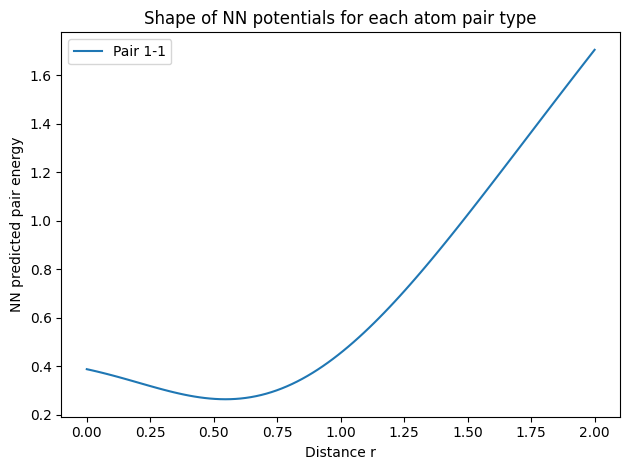

In [6]:
nn_ff.load_state_dict(params_1)

r_vals = torch.linspace(0.0, 2.0, 100)
for i in range(1, max_Za + 1):
    for j in range(i, max_Za + 1):
        energies = [nn_ff.forward_single_pair(r, i, j).item() for r in r_vals]
        plt.plot(r_vals.numpy(), energies, label=f'Pair {i}-{j}')
plt.xlabel('Distance r')
plt.ylabel('NN predicted pair energy')
plt.title('Shape of NN potentials for each atom pair type')
plt.legend()
plt.tight_layout()



  0%|          | 0/201 [00:00<?, ?it/s, alpha_star=4.1452e-02, min_epsilon=N/A, total_scale=2.244688e-02]

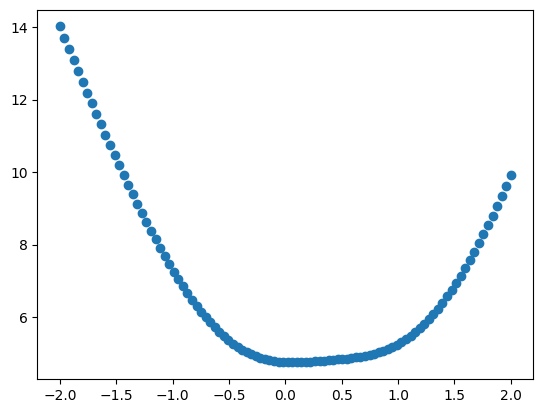

  0%|          | 1/201 [00:00<02:02,  1.63it/s, alpha_star=4.1452e-02, min_epsilon=N/A, total_scale=2.244688e-02]

0.04145243013996061
Iteration 0, alpha_star=4.1452e-02, total_scale=2.244688e-02


 20%|█▉        | 40/201 [00:13<00:52,  3.06it/s, alpha_star=2.6145e-02, min_epsilon=N/A, total_scale=2.391107e-02]

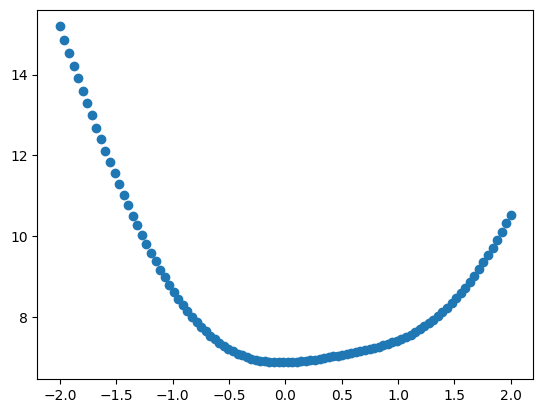

 20%|██        | 41/201 [00:14<00:59,  2.69it/s, alpha_star=2.6145e-02, min_epsilon=N/A, total_scale=2.391107e-02]

0.02614489983093805
Iteration 40, alpha_star=2.6145e-02, total_scale=2.391107e-02


 40%|███▉      | 80/201 [00:28<00:42,  2.82it/s, alpha_star=5.0445e-02, min_epsilon=N/A, total_scale=2.382733e-02]

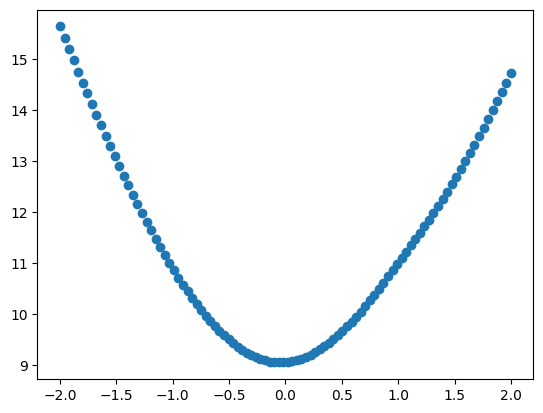

 40%|████      | 81/201 [00:28<00:45,  2.63it/s, alpha_star=5.0445e-02, min_epsilon=N/A, total_scale=2.382733e-02]

0.05044539622114694
Iteration 80, alpha_star=5.0445e-02, total_scale=2.382733e-02


 60%|█████▉    | 120/201 [00:42<00:26,  3.03it/s, alpha_star=1.8248e-02, min_epsilon=N/A, total_scale=8.458962e-03]

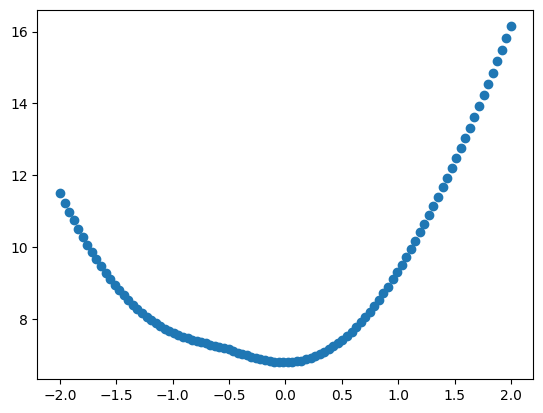

 60%|██████    | 121/201 [00:42<00:30,  2.65it/s, alpha_star=1.8248e-02, min_epsilon=N/A, total_scale=8.458962e-03]

0.018247902717036857
Iteration 120, alpha_star=1.8248e-02, total_scale=8.458962e-03


 80%|███████▉  | 160/201 [00:56<00:13,  3.06it/s, alpha_star=6.0431e-03, min_epsilon=N/A, total_scale=9.785391e-03]

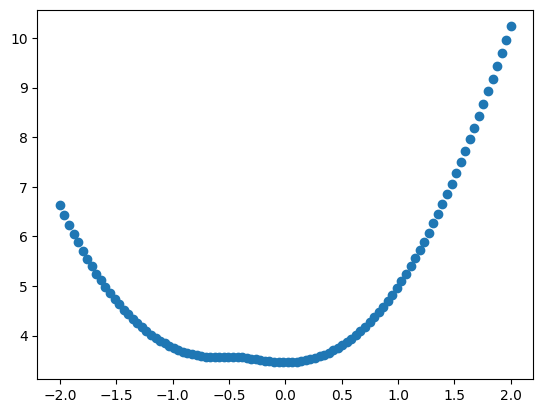

 80%|████████  | 161/201 [00:56<00:15,  2.60it/s, alpha_star=6.0431e-03, min_epsilon=N/A, total_scale=9.785391e-03]

0.0060431251339673414
Iteration 160, alpha_star=6.0431e-03, total_scale=9.785391e-03


100%|█████████▉| 200/201 [01:10<00:00,  2.83it/s, alpha_star=1.8295e-02, min_epsilon=N/A, total_scale=1.157273e-02]

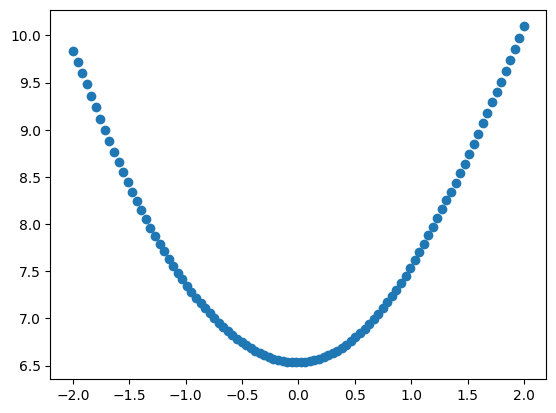

100%|██████████| 201/201 [01:10<00:00,  2.86it/s, alpha_star=1.8295e-02, min_epsilon=N/A, total_scale=1.157273e-02]

0.01829491716383084
Iteration 200, alpha_star=1.8295e-02, total_scale=1.157273e-02
optimization complete


In [ ]:
params_0 = copy.deepcopy(nn_ff.state_dict())
optimizer = LinesearchImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, nn_ff, rmsd_loss,
    Ra_stars=Ra_star_list,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)
new_params = optimizer.optimize(params_0, lr=1e-3, epoch=201, print_period=40, e_size=0.2, eN=9, sg=2)
print('optimization complete')


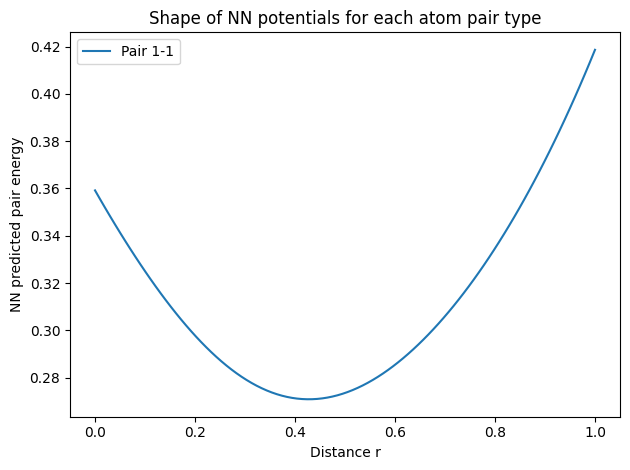

In [11]:
nn_ff.load_state_dict(new_params)

r_vals = torch.linspace(0.0, 1.0, 100)
for i in range(1, max_Za + 1):
    for j in range(i, max_Za + 1):
        energies = [nn_ff.forward_single_pair(r, i, j).item() for r in r_vals]
        plt.plot(r_vals.numpy(), energies, label=f'Pair {i}-{j}')
plt.xlabel('Distance r')
plt.ylabel('NN predicted pair energy')
plt.title('Shape of NN potentials for each atom pair type')
plt.legend()
plt.tight_layout()
